# 04 – Sensitivitätsanalyse

**Team 1 – Physikalisches Basismodell** (§9, Schritt 9; §15 Wochen 5–6)

Sweeps über A_H × Salz (Heatmap, Pflichtplot), Rauschen, Retardierungsparameter
L_r und p, Radius, Core-Parameter, Kontaktdefinition – plus Negativkontrolle
(A_H = 0). Alle Läufe mit dokumentierten, konstanten Seeds.

**Konvention:** vorgeclusterter Start (L₀ = 20 nm, N = 20), dt = 1×10⁻⁷ s,
Kraftbegrenzung 20 pN. Cluster-Metrik: mittlere größte Komponente über das
letzte Viertel des Laufs.

In [1]:
import sys
from pathlib import Path
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from src.constants import DEBYE_LENGTHS
from src.potentials import ProtocellForces
from src.brownian_cluster import BrownianClusterSim, lattice_positions
from src.pair_dynamics import PairBrownian1D, contact_zone
from src.metrics import cluster_metrics, contact_graph, CONTACT_ZONES, escape_time
from src.plots import setup_style, save_fig

setup_style()

DT = 1e-7
FORCE_CAP = 20e-12
BOX = 20e-6
R = 500e-9
SEED = 42
STEPS = 20_000          # Sweep-Läufe
RECORD_EVERY = 50
N_SWEEP = 20


def sweep_run(model, mode, n, steps=STEPS, box=BOX, R_cell=R, gap=20e-9,
              seed=SEED, diffusion=1e-16):
    # Clusterlauf: Rückgabe (mittlere größte Komponente im letzten Viertel,
    # Anteil der Frames mit vollständiger Komponente).
    x0 = lattice_positions(n, box, R_cell, gap, seed=seed)
    sim = BrownianClusterSim(n=n, R=R_cell, box=box, dt=DT, seed=seed,
                             force_cap=FORCE_CAP, diffusion=diffusion, x=x0)
    largest = []
    for step in range(1, steps + 1):
        sim.step(model, mode=mode)
        if step % RECORD_EVERY == 0:
            largest.append(cluster_metrics(sim.pair_distance_table(), n)["largest_cluster"])
    tail = largest[len(largest) // 4:]
    return float(np.mean(tail)), float(np.mean(np.array(tail) == n))


def pair_metrics(A_H, mode, seed=SEED, steps=200_000, diffusion=1e-16, **kw):
    # Paarlauf: Rückgabe (P(L<30 nm), Escape-Zeit aus der Startzone meso_gap)
    sim = PairBrownian1D(ProtocellForces(A_H=A_H, **kw), L0=20e-9, dt=DT,
                         seed=seed, force_cap=FORCE_CAP, diffusion=diffusion)
    traj = sim.run(steps, mode=mode)
    zones = [contact_zone(x) for x in traj]
    et = escape_time(zones)
    return float(np.mean(traj < 30e-9)), (et if et is not None else len(zones))

## Heatmap: A_H × Salz (Pflichtplot)

A_H ∈ {0.2, 0.5, 1, 3, 5, 10}×10⁻²¹ J (Fettsäure- bis PMBC-Bereich, §6) ×
Salz ∈ {50, 100, 200} mM. Farbe = mittlere größte Komponente, Modus cl_retarded.

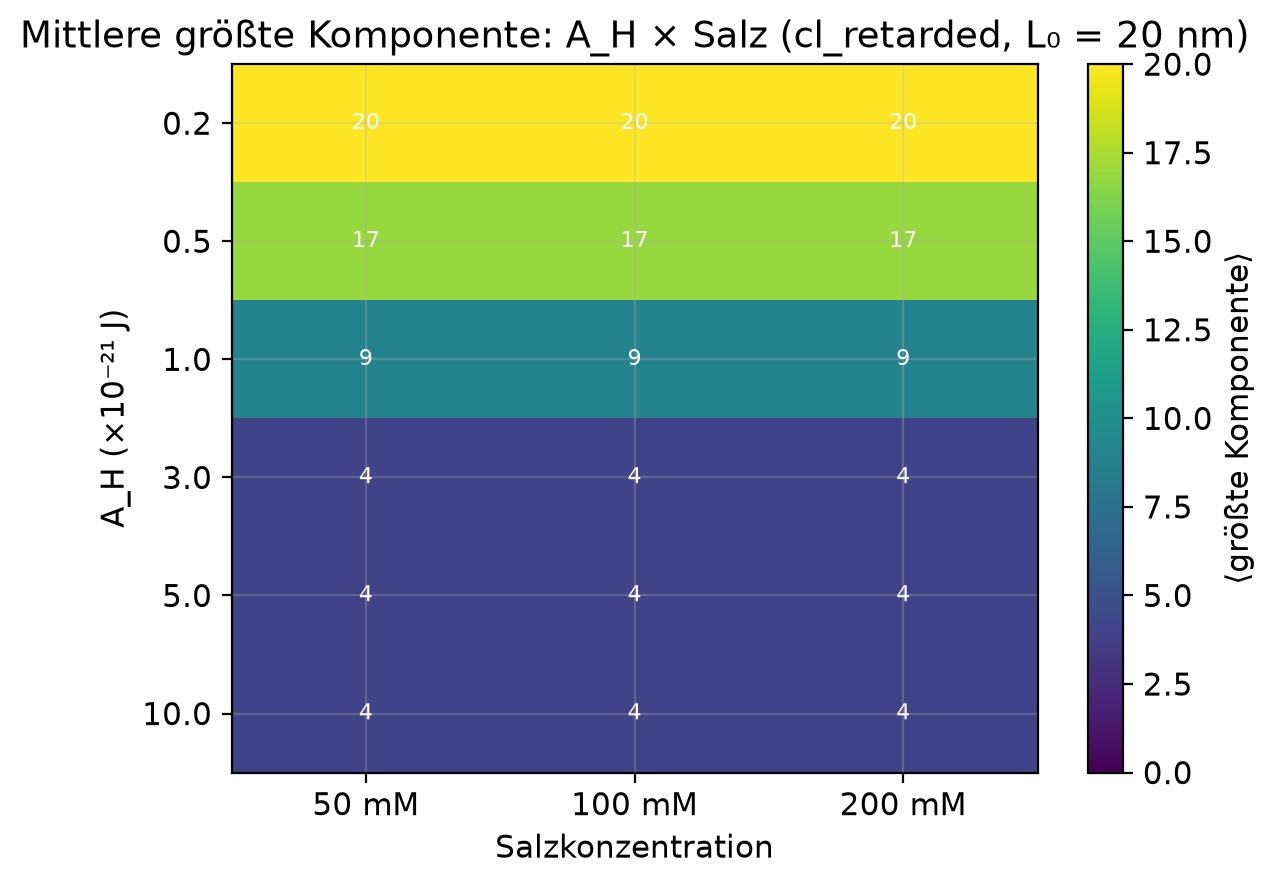

array([[20.        , 20.        , 20.        ],
       [16.92666667, 16.92666667, 16.92666667],
       [ 9.04666667,  9.04666667,  9.04666667],
       [ 4.        ,  4.        ,  4.        ],
       [ 4.        ,  4.        ,  4.        ],
       [ 4.        ,  4.        ,  4.        ]])

In [2]:
A_H_VALUES = [0.2e-21, 0.5e-21, 1e-21, 3e-21, 5e-21, 10e-21]
SALTS = [50, 100, 200]
grid = np.zeros((len(A_H_VALUES), len(SALTS)))
grid_p = np.zeros_like(grid)
for r, A_H in enumerate(A_H_VALUES):
    for c, salt in enumerate(SALTS):
        model = ProtocellForces(A_H=A_H, lambda_D=DEBYE_LENGTHS[salt])
        grid[r, c], grid_p[r, c] = sweep_run(model, "cl_retarded", N_SWEEP)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
im = ax.imshow(grid, cmap="viridis", aspect="auto", vmin=0, vmax=N_SWEEP)
ax.set_xticks(range(len(SALTS)), [f"{s} mM" for s in SALTS])
ax.set_yticks(range(len(A_H_VALUES)), [f"{a/1e-21:.1f}" for a in A_H_VALUES])
ax.set_xlabel("Salzkonzentration"); ax.set_ylabel("A_H (×10⁻²¹ J)")
ax.set_title("Mittlere größte Komponente: A_H × Salz (cl_retarded, L₀ = 20 nm)")
for r in range(len(A_H_VALUES)):
    for c in range(len(SALTS)):
        ax.text(c, r, f"{grid[r, c]:.0f}", ha="center", va="center",
                color="white", fontsize=8)
fig.colorbar(im, label="⟨größte Komponente⟩")
save_fig(fig, "11_heatmap_ah_salz")
plt.show()
grid

**Beobachtung:** Die Clusterpersistenz hängt primär an A_H (Material), kaum am
Salz – Debye-Abschirmung trifft die *Elektrostatik*, nicht die
Fluktuationsbeiträge (§18, Fehler 3: elektrostatische Abschirmung darf nicht auf
vdW/CL übertragen werden). Schwache Materialien (A_H ≤ 0.5×10⁻²¹ J) verlieren
Kontakte, PMBC-artige (A_H ≥ 3×10⁻²¹ J) halten sie.

## Rauschen-Sweep

Diffusionskoeffizient D ∈ {1e-17 … 1e-14} m²/s im Paarmodell: Kontaktwahrscheinlichkeit
P(L < 30 nm) und Escape-Zeit aus meso_gap.

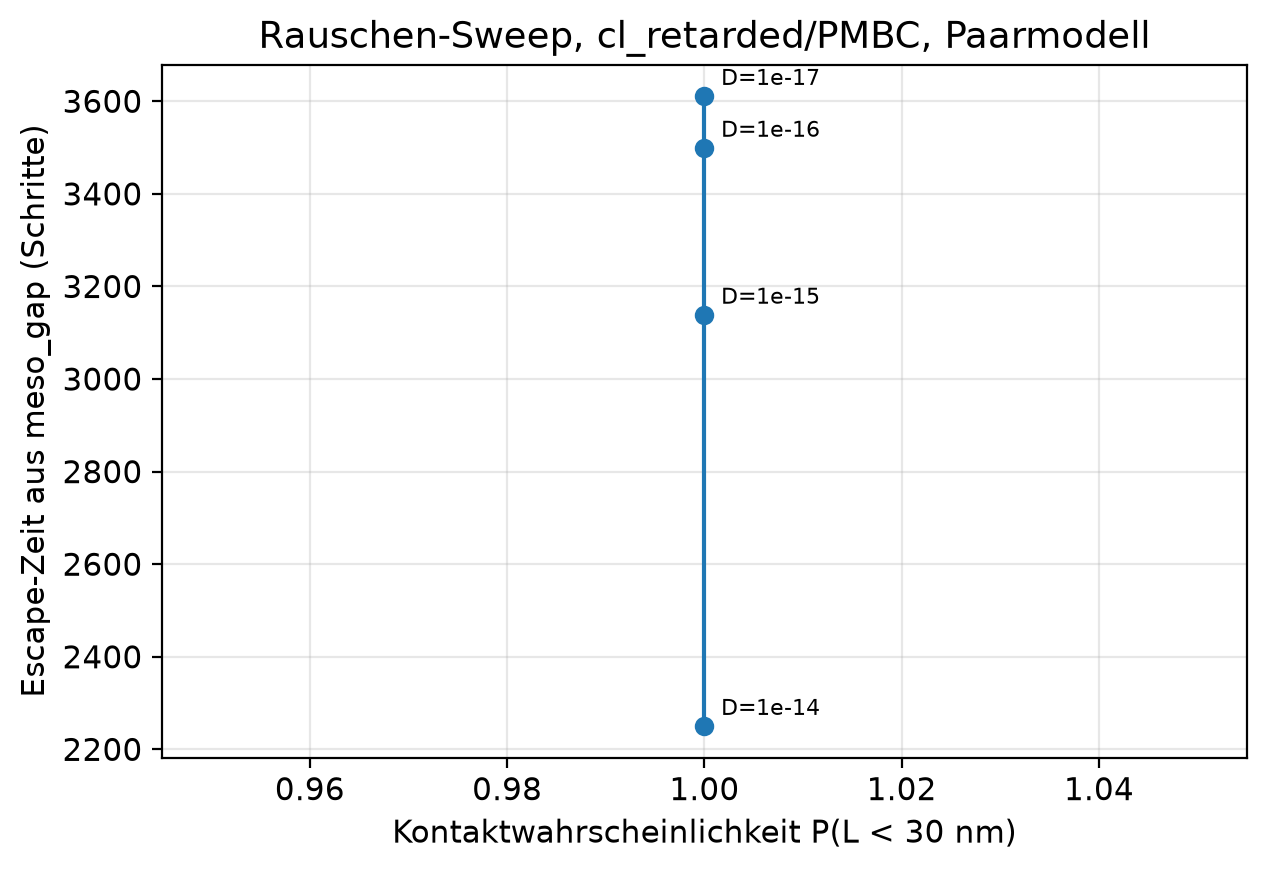

,D (m²/s),P(L<30 nm),Escape meso_gap (Schritte)
0,1.000000e-17,1.0,3611.333333
1,1.000000e-16,1.0,3499.333333
2,1.000000e-15,1.0,3138.666667
3,1.000000e-14,1.0,2250.333333


In [3]:
rows = []
for D in (1e-17, 1e-16, 1e-15, 1e-14):
    cp, esc = [], []
    for seed in (0, 1, 2):
        p, e = pair_metrics(5e-21, "cl_retarded", seed=seed, diffusion=D)
        cp.append(p); esc.append(e)
    rows.append({"D (m²/s)": D, "P(L<30 nm)": np.mean(cp),
                 "Escape meso_gap (Schritte)": np.mean(esc)})
noise_tab = pd.DataFrame(rows)

fig, ax = plt.subplots()
ax.plot(noise_tab["P(L<30 nm)"], noise_tab["Escape meso_gap (Schritte)"], "o-")
for _, r in noise_tab.iterrows():
    ax.annotate(f"D={r['D (m²/s)']:.0e}",
                (r["P(L<30 nm)"], r["Escape meso_gap (Schritte)"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("Kontaktwahrscheinlichkeit P(L < 30 nm)")
ax.set_ylabel("Escape-Zeit aus meso_gap (Schritte)")
ax.set_title("Rauschen-Sweep, cl_retarded/PMBC, Paarmodell")
save_fig(fig, "12_rauschen_sweep")
plt.show()
noise_tab

## Retardierungs-Sweep: L_r × p (Paarmodell)

L_r ∈ {10, 20, 30} nm, p ∈ {1, 2}: wie stark dämpft Retardierung Kontaktbildung
und Persistenz?

In [4]:
rows = []
for L_ret in (10e-9, 20e-9, 30e-9):
    for p in (1, 2):
        cp, esc = [], []
        for seed in (0, 1, 2):
            prob, e = pair_metrics(5e-21, "cl_retarded", seed=seed,
                                   L_ret=L_ret, p_ret=p)
            cp.append(prob); esc.append(e)
        rows.append({"L_r (nm)": L_ret / 1e-9, "p": p,
                     "P(L<30 nm)": np.mean(cp),
                     "Escape meso_gap (Schritte)": np.mean(esc)})
ret_tab = pd.DataFrame(rows)
ret_tab

,L_r (nm),p,P(L<30 nm),Escape meso_gap (Schritte)
0,10.0,1,1.0,2791.666667
1,10.0,2,1.0,7530.666667
2,20.0,1,1.0,1945.333333
3,20.0,2,1.0,3499.333333
4,30.0,1,1.0,1665.333333
5,30.0,2,1.0,2537.333333


## Radius- und Core-Sensitivität

Radius R ∈ {100, 250, 500, 1000} nm (Clusterpersistenz; R geht in Kraft und
Gitter) und Core-Parameter C_core ∈ {0.1, 0.5, 1.0} kBT (Paarkontakt).

In [5]:
rows = []
for R_nm in (100, 250, 500, 1000):
    model = ProtocellForces(A_H=5e-21, R=R_nm * 1e-9)  # R_eff = R/2 folgt mit
    mean_largest, _ = sweep_run(model, "cl_retarded", N_SWEEP, R_cell=R_nm * 1e-9)
    rows.append({"R (nm)": R_nm, "⟨größte Komponente⟩": mean_largest})
radius_tab = pd.DataFrame(rows)

core_rows = []
for C_kBT in (0.1, 0.5, 1.0):
    cp = [pair_metrics(5e-21, "dlvo", seed=s, C_core_kBT=C_kBT)[0] for s in (0, 1, 2)]
    core_rows.append({"C_core (kBT)": C_kBT, "P(L<30 nm)": np.mean(cp)})
core_tab = pd.DataFrame(core_rows)
display(radius_tab); display(core_tab)

,R (nm),⟨größte Komponente⟩
0,100,8.526667
1,250,4.226667
2,500,4.000000
3,1000,4.000000


,C_core (kBT),P(L<30 nm)
0,0.1,1.0
1,0.5,1.0
2,1.0,1.0


## Kontaktdefinitions-Sensitivität (§15, Woche 6)

Dieselbe Endkonfiguration, verschiedene Definitionen: akzeptierte Zonen
schrittweise erweitern – wie stark hängt die Clustermetrik von der Definition ab?

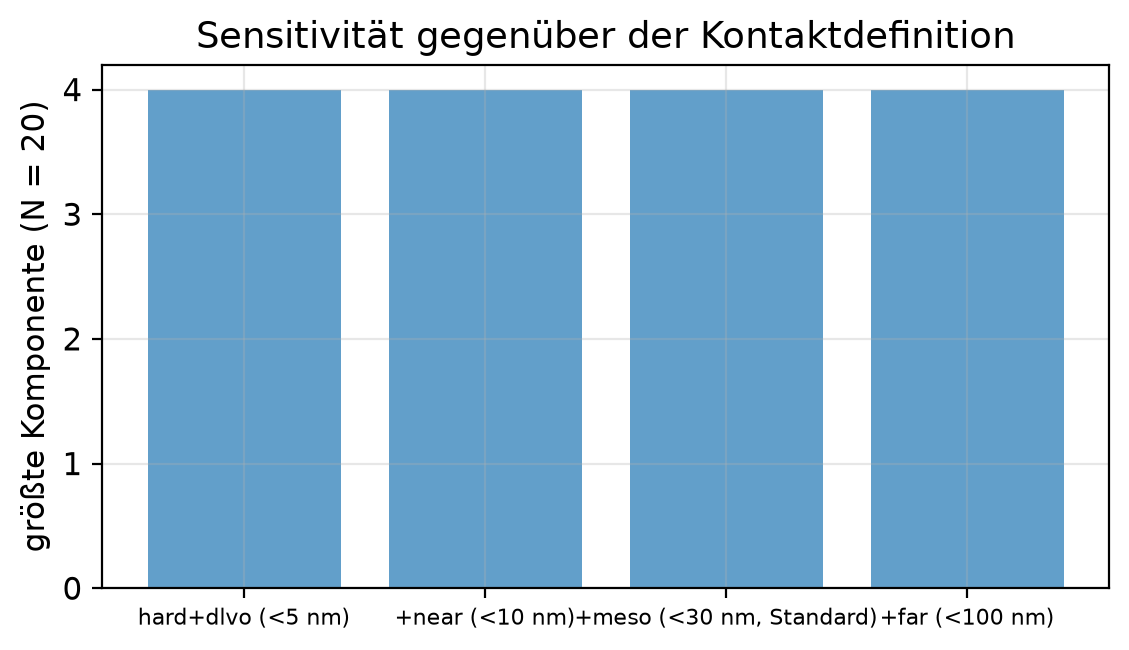

,Definition,größte Komponente,Kanten
0,hard+dlvo (<5 nm),4,25
1,+near (<10 nm),4,25
2,"+meso (<30 nm, Standard)",4,25
3,+far (<100 nm),4,25


In [6]:
model = ProtocellForces(A_H=5e-21)
x0 = lattice_positions(N_SWEEP, BOX, R, 20e-9, seed=SEED)
sim = BrownianClusterSim(n=N_SWEEP, R=R, box=BOX, dt=DT, seed=SEED,
                         force_cap=FORCE_CAP, x=x0)
for _ in range(STEPS):
    sim.step(model, "cl_retarded")
pair_rows = sim.pair_distance_table()

DEFS = {
    "hard+dlvo (<5 nm)": {"hard_contact", "dlvo_zone"},
    "+near (<10 nm)": {"hard_contact", "dlvo_zone", "near_gap"},
    "+meso (<30 nm, Standard)": CONTACT_ZONES,
    "+far (<100 nm)": CONTACT_ZONES | {"far_gap"},
}
rows = []
for label, zones in DEFS.items():
    g = contact_graph(pair_rows, N_SWEEP, accepted_zones=zones)
    largest = max(len(c) for c in nx.connected_components(g)) if g.number_of_edges() else 1
    rows.append({"Definition": label, "größte Komponente": largest,
                 "Kanten": g.number_of_edges()})
def_tab = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(def_tab["Definition"], def_tab["größte Komponente"], color="tab:blue", alpha=0.7)
ax.set_ylabel("größte Komponente (N = 20)")
ax.set_title("Sensitivität gegenüber der Kontaktdefinition")
plt.xticks(fontsize=8)
save_fig(fig, "13_kontaktdefinition")
plt.show()
def_tab

## Negativkontrolle: A_H = 0

Vorgeclusterter Start ohne Anziehung (A_H = 0) bei erhöhtem Rauschen
D = 1×10⁻¹⁴ m²/s. Beim Referenz-D des Aufgabenblatts (1×10⁻¹⁶ m²/s) diffundiert
in machbarer Zeit praktisch nichts – die Kontrolle wäre trivial. Mit
D = 1×10⁻¹⁴ verdampft ein kraftloses Aggregat messbar; mit Anziehung bleibt es
stabil.

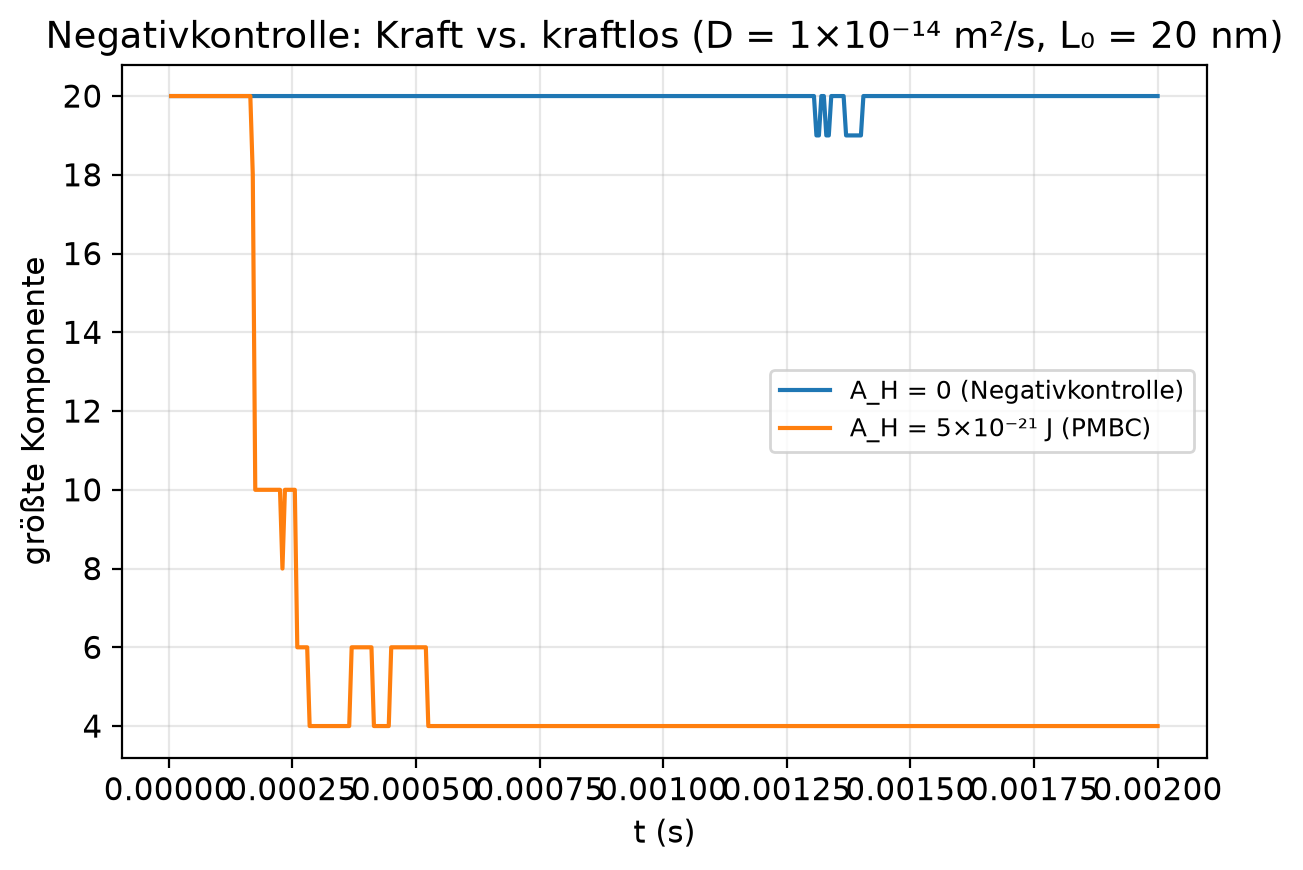

In [7]:
D_NC = 1e-14
results = {}
for label, A_H in [("A_H = 0 (Negativkontrolle)", 0.0), ("A_H = 5×10⁻²¹ J (PMBC)", 5e-21)]:
    model = ProtocellForces(A_H=A_H)
    x0 = lattice_positions(N_SWEEP, BOX, R, 20e-9, seed=SEED)
    sim = BrownianClusterSim(n=N_SWEEP, R=R, box=BOX, dt=DT, seed=SEED,
                             force_cap=FORCE_CAP, diffusion=D_NC, x=x0)
    trace = []
    for step in range(1, STEPS + 1):
        sim.step(model, "cl_retarded")
        if step % RECORD_EVERY == 0:
            trace.append(cluster_metrics(sim.pair_distance_table(), N_SWEEP)["largest_cluster"])
    results[label] = trace

fig, ax = plt.subplots()
for label, trace in results.items():
    ax.plot(np.arange(1, len(trace) + 1) * RECORD_EVERY * DT, trace, label=label)
ax.set_xlabel("t (s)"); ax.set_ylabel("größte Komponente")
ax.set_title("Negativkontrolle: Kraft vs. kraftlos (D = 1×10⁻¹⁴ m²/s, L₀ = 20 nm)")
ax.legend(fontsize=9)
save_fig(fig, "14_negativkontrolle")
plt.show()

## Interpretation (streng nach §10)

- **Material dominiert, Salz kaum:** Clusterpersistenz skaliert mit A_H; Debye-Screening
  ändert die Fluktuationsbeiträge nicht exponentiell (§18, Fehler 3).
- **Rauschen konkurriert mit Bindung:** bei D ≥ 1×10⁻¹⁵ m²/s sinkt P(L < 30 nm)
  und die Escape-Zeiten verkürzen sich – Persistenz ist eine Rauschfrage, nicht nur
  eine Kraftfrage.
- **Retardierung dämpft, nie verstärkt** (§18, Fehler 4): größere L_r/p senken
  Kontaktwahrscheinlichkeit und Verweildauer.
- **Kontaktdefinition ist ein Ergebnisparameter:** die Clustergröße hängt stark von
  der Zonenauswahl ab – für Team 2 ist die Standarddefinition (L < 30 nm) dokumentiert.
- **Negativkontrolle bestätigt:** ohne Anziehung verdampft das Aggregat; die
  beobachtete Persistenz ist kraftvermittelt, kein Startartefakt.
- **Gesamt:** Standard-Lifshitz-/CL-Kopplung kann im Bereich 2–30 nm plausibel zur
  Stabilisierung beitragen, besonders für PMBC-artige Protozellen. Für 30–100 nm sind
  Einzelpaar-Kräfte wahrscheinlich schwach; robuste Clusterbildung erfordert
  Mehrkörper-, Geometrie- oder Gap-Effekte. CL erklärt 2–100 nm nicht vollständig.